# Introductory Examples

Focuses on 3 main quantitative topics:
* Implied Volatilites
* Monte Carlo Simulations
    * Monte Carlo simulation is a cornerstone for numerical option pricing as well as for risk management efforts involving value-at-risk calculations or credit value
adjustments.
* Technical Analysis
    * An analysis of historical time series data is implemented to backtest an investment strategy based on trend signals

In [23]:
# import packages

import pandas as pd
import pandas_datareader.data as web
import numpy as np
import yfinance as yf
import matplotlib
from math import log, sqrt, exp
from scipy import stats
import matplotlib.pyplot as plt
from time import time
import warnings

# Ignore both FutureWarning and SettingWithCopyWarning
warnings.simplefilter(action = 'ignore', category = FutureWarning)
warnings.simplefilter(action = 'ignore', category = UserWarning)
pd.options.mode.chained_assignment = None  # Disables SettingWithCopyWarning

## Implied Volatilities

### *Black-Scholes-Merton Model (BSM)*
Per Corporate Finance Institute:
* The BSM model is used to determine the fair prices of stock options based on six variables: volatility, type, underlying stock price, strike price, time, and risk-free rate
* Pricing is of two types: pricing call and pricing put options

The model equation is in REFERENCE FILES

Assumptions of the BSM Model:
* Lognormal distribution: The Black-Scholes-Merton model assumes that stock prices follow a lognormal distribution based on the principle that asset prices cannot take a negative value; they are bounded by zero
* No dividends: The BSM model assumes that the stocks do not pay any dividends or returns
* Expiration date: The model assumes that the options can only be exercised on its expiration or maturity date. Hence, it does not accurately price American options. It is extensively used in the European options market 
* Random walk: The stock market is a highly volatile one, and hence, a state of random walk is assumed as the market direction can never truly be predicted 
* Frictionless market: No transaction costs, including commission and brokerage, is assumed in the BSM model
* Risk-free interest rate: The interest rates are assumed to be constant, hence making the underlying asset a risk-free one
* Normal distribution: Stock returns are normally distributed. It implies that the volatility of the market is constant over time
* No arbitrage: There is no arbitrage. It avoids the opportunity of making a riskless profit

Limitations of the BSM MOdel:
* Limited to the European market: As mentioned earlier, the Black-Scholes-Merton model is an accurate determinant of European option prices. It does not accurately value stock options in the US. It is because it assumes that options can only be exercised on its expiration/maturity date
* Risk-free interest rates: The BSM model assumes constant interest rates, but it is hardly ever the reality
* Assumption of a frictionless market: Trading generally comes with transaction costs such as brokerage fees, commission, etc. However, the Black Scholes Merton model assumes a frictionless market, which means that there are no transaction costs. It is hardly ever the reality in the trading market
* No returns: The BSM model assumes that there are no returns associated with the stock options. There are no dividends and no interest earnings. However, it is not the case in the actual trading market. The buying and selling of options are primarily focused on the returns

In [11]:
# read in VSTOXX data
reference_path = '/Users/duanemadziva/Documents/Programming/GitHub Repositories/Python-Finance/REFERENCE FILES/'

h5 = pd.HDFStore(reference_path+'vstoxx_data_31032014.h5', 'r')
futures_data = h5['futures_data'] # VSTOXX futures data
options_data = h5['options_data'] # VSTOXX call option data
h5.close()

### Helper Functions For BSM Model

In [12]:
def bsm_call_value(S0, K, T, r, sigma):
    """
    Parameters
    ==========
    S0 : float
    initial stock/index level
    K : float
    strike price
    T : float
    maturity date (in year fractions)
    r : float
    constant risk-free short rate
    sigma : float
    volatility factor in diffusion term
    Returns
    =======
    value : float
    present value of the European call option
    """
    S0 = float(S0)
    d1 = (log(S0 / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * sqrt(T))
    d2 = (log(S0 / K) + (r - 0.5 * sigma ** 2) * T) / (sigma * sqrt(T))
    # stats.norm.cdf --> cumulative distribution function
    value = (S0 * stats.norm.cdf(d1, 0.0, 1.0) - K * exp(-r * T) * stats.norm.cdf(d2, 0.0, 1.0))

    return value

In [13]:
def bsm_vega(S0, K, T, r, sigma):
    """
    Vega of European option in BSM model.
    Parameters
    ==========
    S0 : float
    initial stock/index level
    K : float
    strike price
    T : float
    maturity date (in year fractions)
    r : float
    constant risk-free short rate
    sigma : float
    volatility factor in diffusion term
    Returns
    =======
    vega : float
    partial derivative of BSM formula with respect
    to sigma, i.e. Vega
    """
    S0 = float(S0)
    d1 = (log(S0 / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * sqrt(T))
    vega = S0 * stats.norm.cdf(d1, 0.0, 1.0) * sqrt(T)
    
    return vega

In [14]:
# Implied volatility function
def bsm_call_imp_vol(S0, K, T, r, C0, sigma_est, it=100):
    """
    Implied volatility of European call option in BSM model.
    Parameters
    ==========
    S0 : float
    initial stock/index level
    K : float
    strike price
    T : float
    maturity date (in year fractions)
    r : float
    constant risk-free short rate
    sigma_est : float
    estimate of impl. volatility
    it : integer
    number of iterations
    Returns
    =======
    simga_est : float
    numerically estimated implied volatility
    """
    for i in range(it):
        sigma_est -= ((bsm_call_value(S0, K, T, r, sigma_est) - C0)/ bsm_vega(S0, K, T, r, sigma_est))
    
    return sigma_est

Let us start with the day from which the quotes are taken; i.e., our t = 0 reference day. This is March 31, 2014. At this day, the closing value of the index was V0 = 17.6639 (we change from S to V to indicate that we are now working with the volatility index). We therefore want to restrict the analysis to those call options with a certain (forward) moneyness, given the value of the future for the respective maturity. We allow a maximum deviation of 50% from the futures level:

In [15]:
V0 = 17.6639 # closing value of the index/ underlying asset
r = 0.01 # risk-free short rate
# add a new column for implied volatilities
options_data['IMP_VOL'] = 0.0

# calculating implied volatility
tol = 0.5 # tolerance level for moneyness

for option in options_data.index:
    #iterating over all option quotes
    forward = futures_data[futures_data['MATURITY'] == \
                           options_data.loc[option]['MATURITY']]['PRICE'].values[0]
    # picking the right futures value
    if (forward * (1 - tol) < options_data.loc[option]['STRIKE'] < forward * (1 + tol)):
        # only for options with moneyness within tolerance
        imp_vol = bsm_call_imp_vol(
            V0, # VSTOXX value
            options_data.loc[option]['STRIKE'],
            options_data.loc[option]['TTM'],
            r, # short rate
            options_data.loc[option]['PRICE'],
            sigma_est = 2., # estimate for implied volatility
            it = 100
        )

        options_data['IMP_VOL'].loc[option] = imp_vol

# visualize options with implied volatility > 0
options_data[options_data['IMP_VOL'] > 0].head()

,DATE,EXP_YEAR,EXP_MONTH,TYPE,STRIKE,PRICE,MATURITY,TTM,IMP_VOL
46178,2014-03-31,2014,4,C,9.0,8.85,2014-04-18,0.049,2.083386
46179,2014-03-31,2014,4,C,10.0,7.85,2014-04-18,0.049,1.804194
46180,2014-03-31,2014,4,C,11.0,6.85,2014-04-18,0.049,1.550283
46181,2014-03-31,2014,4,C,12.0,5.85,2014-04-18,0.049,1.316103
46182,2014-03-31,2014,4,C,13.0,4.85,2014-04-18,0.049,1.097184


As in stock or foreign exchange markets, you will notice the so-called volatility smile, which is most pronounced for the shortest maturity and which becomes
a bit less pronounced for the longer maturities

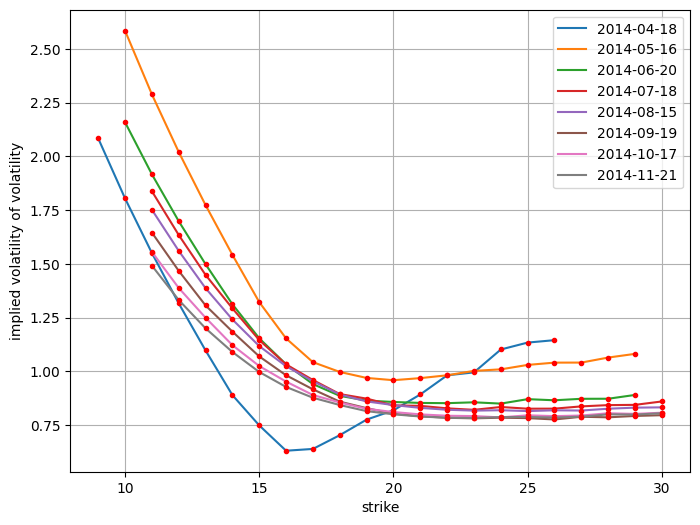

In [16]:
# visualize the implied volatility
plot_data = options_data[options_data['IMP_VOL'] > 0]
# since all maturities appear multiple times, we need to use a little trick to get to a nonredundent, sorted list with the maturities
maturities = sorted(set(options_data['MATURITY']))

%matplotlib inline
plt.figure(figsize=(8, 6))
for maturity in maturities:
    data = plot_data[options_data.MATURITY == maturity]
    # select data for this maturity
    plt.plot(
        data['STRIKE'],
        data['IMP_VOL'],
        label = maturity.date(),
        lw = 1.5
    )
    plt.plot(
        data['STRIKE'],
        data['IMP_VOL'],
        'r.'
    )
plt.grid(True)
plt.xlabel('strike')
plt.ylabel('implied volatility of volatility')
plt.legend()
plt.show()

## Monte Carlo Simmulation

* One of the most important algorithms in finance and numerical science in general. Its importance stems from the fact that it is quite powerful when it comes to option pricing or risk management problems
* The downside of the Monte Carlo method is that it is per se computationally demanding and often needs huge amounts of memory even for quite simple problems, necessitating the need to apply it efficiently
* Can be done in 3 approaches:
    * Pure python - using standard libraries that come with python installation
    * Vectorized numpy - using numpy
    * Fully vectorized numpy - combines mathematical formulations with vectorization capabilities of numpy


## Graphical Analysis

Assume a Monte carlo simulation using vectorized numpy below:

In [19]:
# Monte Carlo valuation of European call options with NumPy

np.random.seed(20000)
t0 = time()

# Parameters
S0 = 100.; K = 105.; T = 1.0; r = 0.05; sigma = 0.2
M = 50; dt = T / M; I = 250000
# Simulating I paths with M time steps
S = np.zeros((M + 1, I))
S[0] = S0
for t in range(1, M + 1):
    z = np.random.standard_normal(I) # pseudorandom numbers
    S[t] = (S[t - 1] * np.exp((r - 0.5 * sigma ** 2) * dt) + (sigma * sqrt(dt) * z))
# vectorized operation per time step over all paths
# Calculating the Monte Carlo estimator
C0 = exp(-r * T) * np.sum(np.maximum(S[-1] - K, 0)) / I
# Results output
tnp1 = time() - t0
print(f"European Option Value {C0:7.3f}")
print(f"Duration in Seconds {tnp1:7.3f}")

European Option Value   0.000
Duration in Seconds   0.175


We can plot the first 10 simulated paths over all time steps from above (S):

Text(0, 0.5, 'index level')

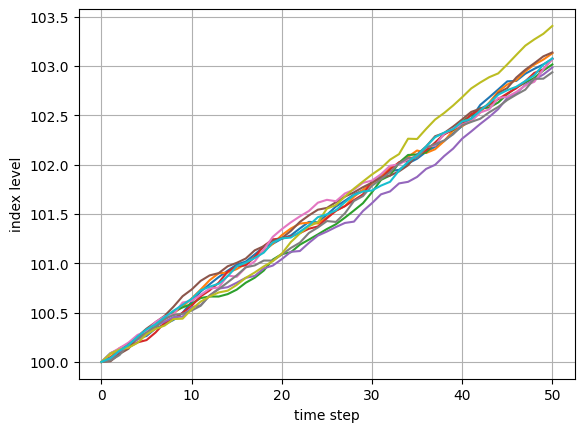

In [20]:
plt.plot(S[:, :10])
plt.grid(True)
plt.xlabel('time step')
plt.ylabel('index level')

Second, we want to see the frequency of the simulated index levels at the end of the simulation period

Text(0, 0.5, 'frequency')

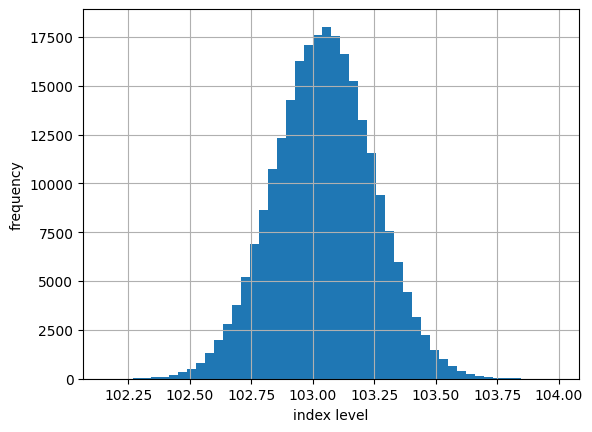

In [21]:
plt.hist(S[-1], bins=50)
plt.grid(True)
plt.xlabel('index level')
plt.ylabel('frequency')

The same type of figure looks completely different for the option’s end-of-period (maturity) inner values as illustrtaed below. In this case, the majority of the simluated values are zero, indicating that the European call option expires worthless in a significant amount of cases

(0.0, 50000.0)

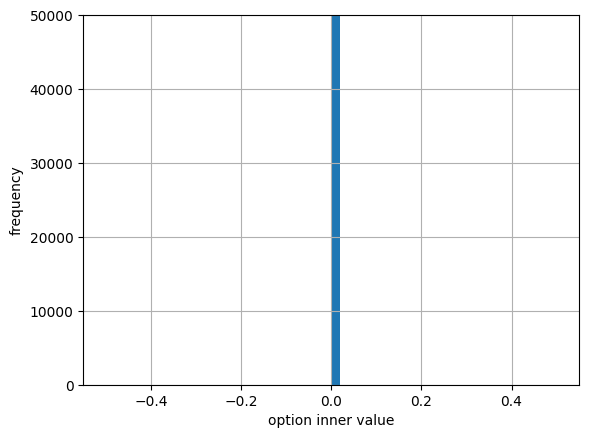

In [22]:
plt.hist(np.maximum(S[-1] - K, 0), bins=50)
plt.grid(True)
plt.xlabel('option inner value')
plt.ylabel('frequency')
plt.ylim(0, 50000)

## Technical Analysis

* In finance, technical analysis is a security analysis methodology for forecasting the direction of prices through the study of past market data, primarily price and volume

[*********************100%***********************]  1 of 1 completed


<Axes: xlabel='Date'>

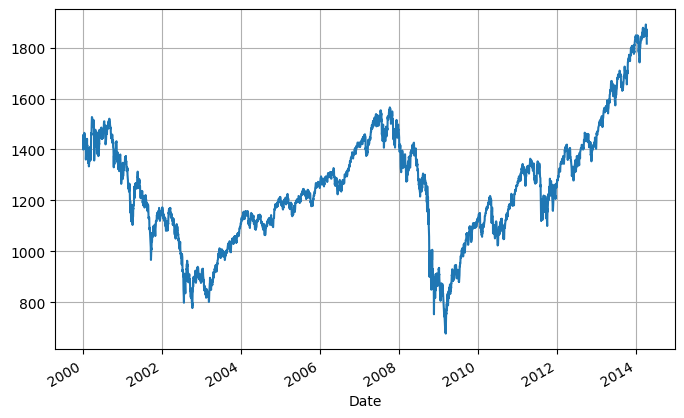

In [35]:
sp500 = yf.download(
    "^GSPC",
    start = "2000-01-01",
    end = "2014-04-14"
)

sp500.columns = sp500.columns.get_level_values('Price') # remove multi-index

# plot closing price on a daily
sp500['Close'].plot(grid = True, figsize = (8, 5))

The trend strategy we want to implement is based on both a two-month (i.e., 42 trading days) and a one-year (i.e., 252 trading days) trend (i.e., the moving average of the index level for the respective period)

<Axes: xlabel='Date'>

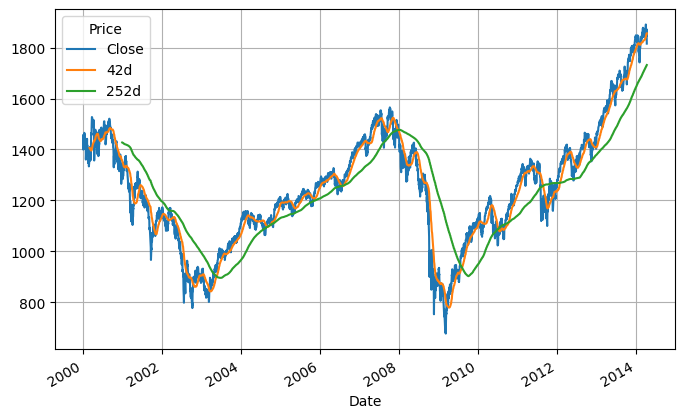

In [36]:
sp500['42d'] = sp500['Close'].rolling(window = 42).mean()#.round(2)
sp500['252d'] = sp500['Close'].rolling(window = 252).mean()#.round(2)

sp500.tail()

# plot 42d and 252d trendlines
sp500[['Close', '42d', '252d']].plot(grid=True, figsize=(8, 5))

Our basic data set is mainly complete, such that we now can devise a rule to generate trading signals. The rule says the following:
* Buy signal (go long)
    * the 42d trend is for the first time SD points above the 252d trend.
* Wait (park in cash)
    * the 42d trend is within a range of +/– SD points around the 252d trend.
* Sell signal (go short)
    * the 42d trend is for the first time SD points below the 252d trend.